In [22]:
import warnings
from urllib3.exceptions import NotOpenSSLWarning

warnings.filterwarnings("ignore", category=NotOpenSSLWarning)
warnings.filterwarnings("ignore", message=".*'M' is deprecated.*")
warnings.filterwarnings("ignore", message=".*previous implementation of stack is deprecated.*")

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

BASE_DIR = Path.cwd()
if not (BASE_DIR / "data").exists() and (BASE_DIR.parent / "data").exists():
    BASE_DIR = BASE_DIR.parent

DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"
PLOTS_DIR = RESULTS_DIR / "plots"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

stock_prices = pd.read_csv(DATA_DIR / "stock_prices.csv")
sp500 = pd.read_csv(DATA_DIR / "sp500.csv")

stock_prices["Date"] = pd.to_datetime(stock_prices["Date"])
sp500["Date"] = pd.to_datetime(sp500["Date"])

stock_prices = stock_prices.sort_values("Date").reset_index(drop=True)
sp500 = sp500.sort_values("Date").reset_index(drop=True)

stock_prices.head()

,Date,A,AA,AAPL,ABBV,ABC,ABT,ACE,ACI,ACN,...,XOM,XRAY,XRX,XYL,YHOO,YUM,ZION,ZLC,ZMH,ZNGA
0,2000-12-12,38.407538,24.494157,1.040282,NaN,9.300100,40.196083,31.011163,4.238186,NaN,...,31.374321,11.567392,4.709992,NaN,17.905,7.531124,49.197351,13.19,NaN,NaN
1,2000-12-13,39.038160,25.323023,1.014579,NaN,9.513010,41.493506,29.534441,4.238186,NaN,...,31.783898,11.743036,4.872700,NaN,17.440,7.292677,48.738634,12.81,NaN,NaN
2,2000-12-14,39.749286,24.594860,0.976702,NaN,9.766690,38.538265,28.796080,4.238186,NaN,...,30.990116,11.567392,5.403645,NaN,16.000,7.109094,47.640991,12.94,NaN,NaN
3,2000-12-15,38.159315,23.967401,0.950999,NaN,10.419011,37.489114,28.102020,4.100917,NaN,...,30.489925,11.683442,5.352263,NaN,16.500,7.056340,46.690792,12.47,NaN,NaN
4,2000-12-18,38.239820,25.028660,0.963850,NaN,10.899191,39.691530,29.165260,4.289662,NaN,...,31.309079,11.918679,5.463590,NaN,16.000,7.398184,47.821201,12.25,NaN,NaN


In [23]:
missing_per_variable = stock_prices.isna().sum().sort_values(ascending=False)

missing_per_year = (
    stock_prices.assign(year=stock_prices["Date"].dt.year)
    .drop(columns="Date")
    .groupby("year")
    .agg(lambda col: col.isna().sum())
    .sum(axis=1)
    .rename("missing_values")
)

print("Missing values per variable:")
display(missing_per_variable.head(20))

print("\nMissing values per year:")
display(missing_per_year)

Missing values per variable:


GOOG    3456
NWSA    3264
ABBV    3137
ADT     3086
KRFT    3069
FB      2992
PSX     2968
ZNGA    2890
WPX     2886
TRIP    2882
DLPH    2867
GRPN    2856
XYL     2843
MPC     2764
P       2759
KMI     2672
ECYT    2664
GM      2616
MCP     2534
TSLA    2514
dtype: int64


Missing values per year:


year
2000     1170
2001    27628
2002    22023
2003    20443
2004    20397
2005    17205
2006    15147
2007    13959
2008    11032
2009    11260
2010     9924
2011     7717
2012     7221
2013     5264
2014     6327
Name: missing_values, dtype: int64

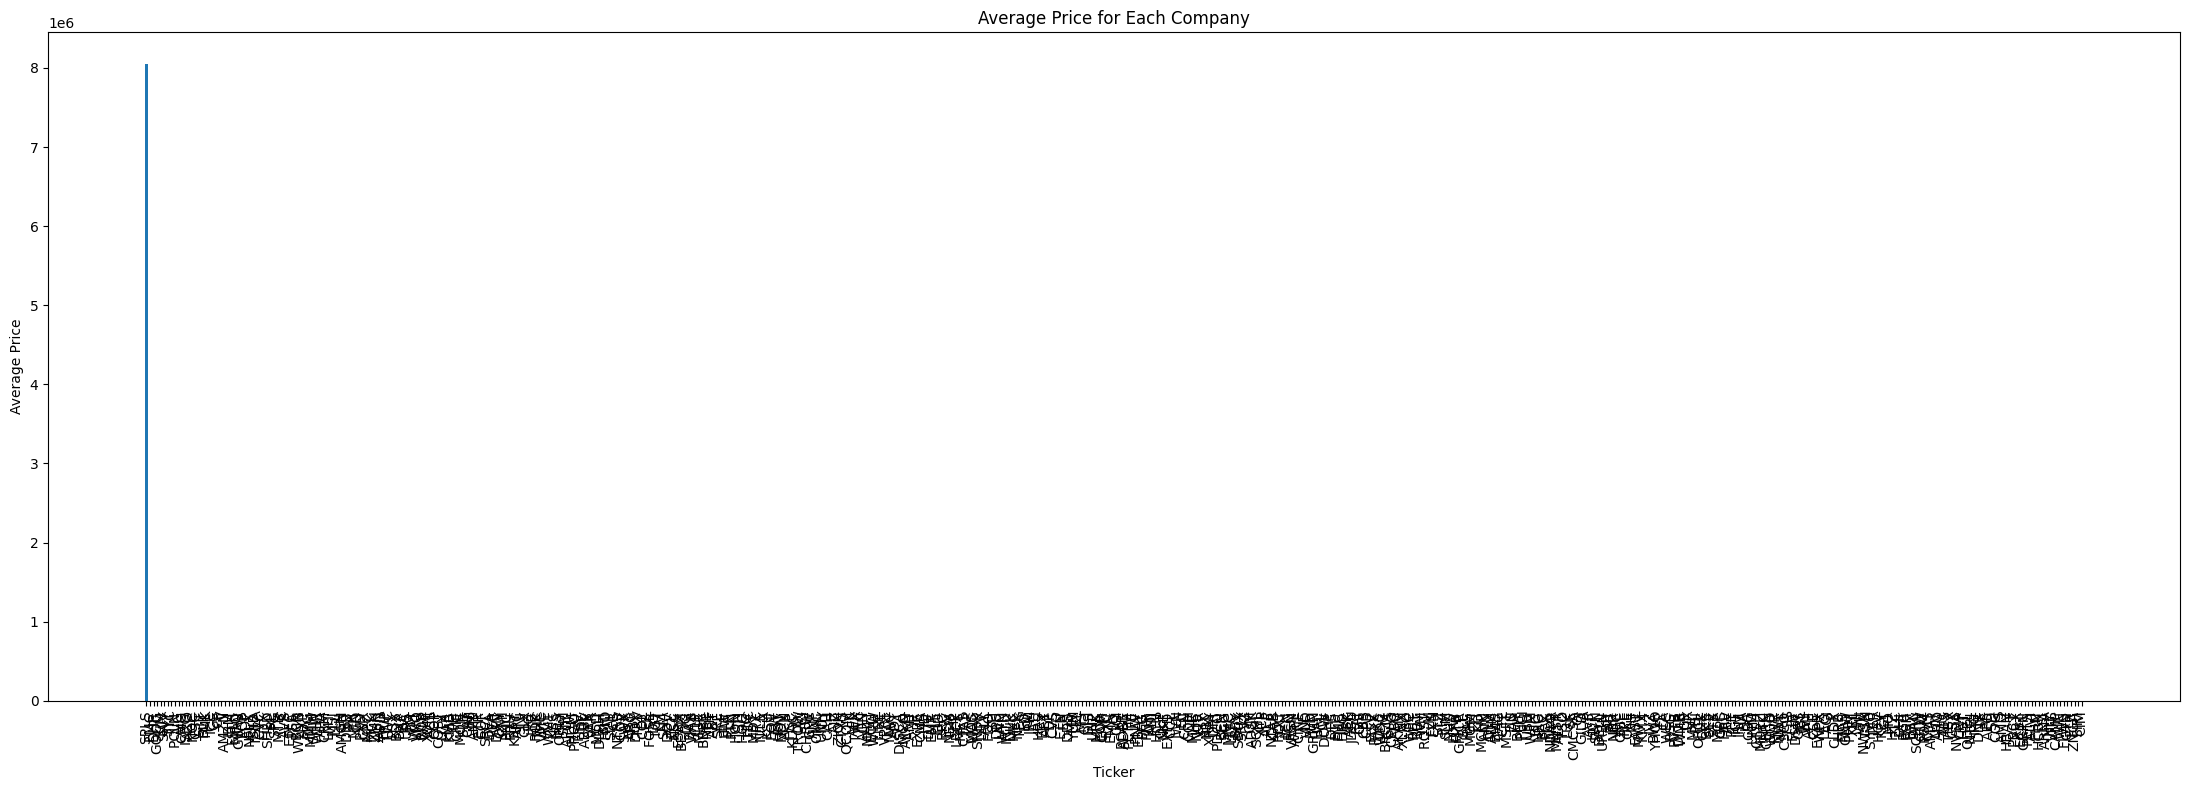

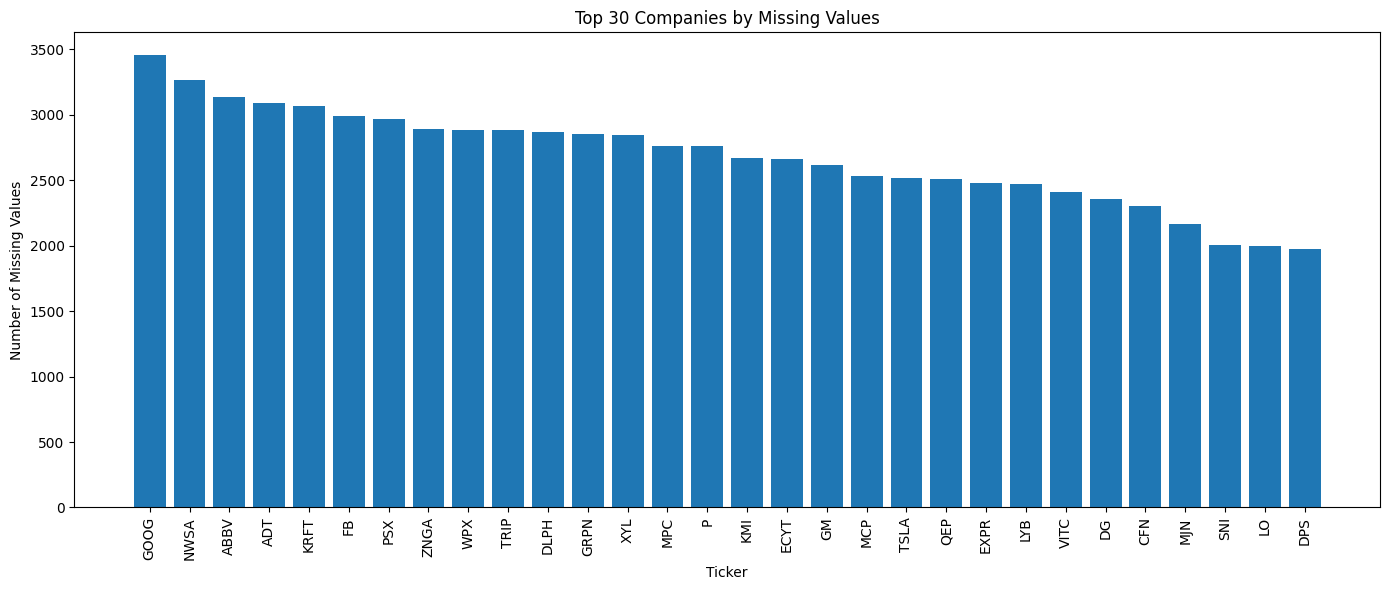

In [24]:
def save_average_price_per_company_plot(prices_df, plot=False):
    avg_price = prices_df.drop(columns="Date").mean(skipna=True).sort_values(ascending=False)

    fig, ax = plt.subplots(figsize=(22, 8))
    ax.bar(avg_price.index, avg_price.values)
    ax.set_title("Average Price for Each Company")
    ax.set_xlabel("Ticker")
    ax.set_ylabel("Average Price")
    ax.tick_params(axis="x", rotation=90)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "average_price_per_company.png", dpi=150)

    if plot:
        plt.show()
    else:
        plt.close(fig)

    return avg_price


def save_missing_values_top_companies_plot(prices_df, plot=False, top_n=30):
    missing_counts = prices_df.drop(columns="Date").isna().sum().sort_values(ascending=False).head(top_n)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.bar(missing_counts.index, missing_counts.values)
    ax.set_title(f"Top {top_n} Companies by Missing Values")
    ax.set_xlabel("Ticker")
    ax.set_ylabel("Number of Missing Values")
    ax.tick_params(axis="x", rotation=90)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "missing_values_top_companies.png", dpi=150)

    if plot:
        plt.show()
    else:
        plt.close(fig)

    return missing_counts


avg_price_per_company = save_average_price_per_company_plot(stock_prices, plot=True)
_ = save_missing_values_top_companies_plot(stock_prices, plot=True)

In [25]:
long_prices = (
    stock_prices.melt(id_vars="Date", var_name="ticker", value_name="price")
    .sort_values(["ticker", "Date"])
    .reset_index(drop=True)
)

long_prices["daily_return"] = long_prices.groupby("ticker")["price"].pct_change(fill_method=None)

price_outliers = long_prices[
    ((long_prices["price"] < 0.1) | (long_prices["price"] > 10000))
    & long_prices["price"].notna()
].copy()

return_outliers = long_prices[
    ((long_prices["daily_return"] > 1) | (long_prices["daily_return"] < -0.5))
    & (~long_prices["Date"].dt.year.isin([2008, 2009]))
    & long_prices["price"].notna()
].copy()

print("Price outliers:", len(price_outliers))
print("Return outliers:", len(return_outliers))

display(price_outliers.head(10))
display(return_outliers.head(10))

Price outliers: 31704
Return outliers: 2072


,Date,ticker,price,daily_return
444568,2000-12-12,CSC,0.0,NaN
444569,2000-12-13,CSC,0.0,NaN
444570,2000-12-14,CSC,0.0,NaN
444571,2000-12-15,CSC,0.0,NaN
444572,2000-12-18,CSC,0.0,NaN
444573,2000-12-19,CSC,0.0,NaN
444574,2000-12-20,CSC,0.0,NaN
444575,2000-12-21,CSC,0.0,NaN
444576,2000-12-22,CSC,0.0,NaN
444577,2000-12-26,CSC,0.0,NaN


,Date,ticker,price,daily_return
49003,2007-04-02,ADP,3.659642e+01,-0.793637
171734,2002-10-01,ARO,1.925926e+00,-0.577922
194376,2005-10-03,AXP,4.390351e+01,-0.711500
375640,2002-02-20,CLDX,1.272000e+01,-0.646667
380026,2005-01-03,CLF,4.386592e+01,-0.513769
444130,2013-04-18,CRM,4.103000e+01,-0.754825
448024,2014-04-03,CSC,1.399589e-317,inf
448025,2014-04-04,CSC,1.277711e-315,90.291831
448026,2014-04-07,CSC,6.706802e-314,51.490776
448027,2014-04-08,CSC,4.222249e-312,61.954727


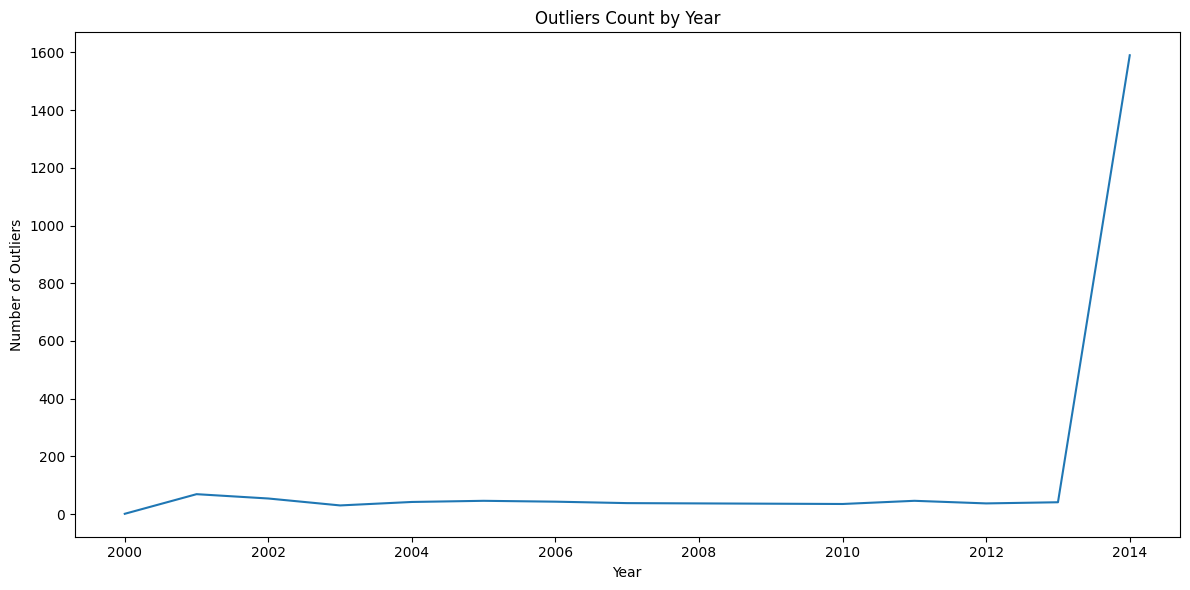

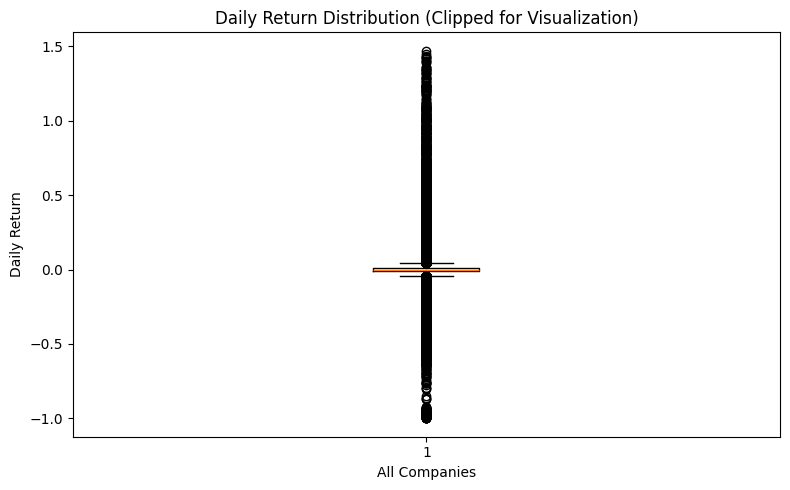

In [26]:
def save_outliers_distribution_plot(outliers_df, plot=False):
    plot_df = outliers_df.copy()
    plot_df["year"] = plot_df["Date"].dt.year
    counts = plot_df.groupby("year").size()

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(counts.index, counts.values)
    ax.set_title("Outliers Count by Year")
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of Outliers")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "outliers_count_by_year.png", dpi=150)

    if plot:
        plt.show()
    else:
        plt.close(fig)

    return counts


def save_daily_return_boxplot(long_df, plot=False):
    sample_returns = long_df["daily_return"].dropna()
    sample_returns = sample_returns[(sample_returns >= -1.5) & (sample_returns <= 1.5)]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.boxplot(sample_returns.values, vert=True)
    ax.set_title("Daily Return Distribution (Clipped for Visualization)")
    ax.set_xlabel("All Companies")
    ax.set_ylabel("Daily Return")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "daily_return_boxplot.png", dpi=150)

    if plot:
        plt.show()
    else:
        plt.close(fig)


_ = save_outliers_distribution_plot(return_outliers, plot=True)
save_daily_return_boxplot(long_prices, plot=True)

In [29]:
import io
import contextlib
import numpy as np
import pandas as pd
import yfinance as yf

candidate_outliers = pd.concat([price_outliers, return_outliers], axis=0).drop_duplicates()
candidate_outliers = candidate_outliers.sort_values(["ticker", "Date"]).reset_index(drop=True)


def to_yf_ticker(ticker):
    return str(ticker).replace(".", "-")


def get_external_close(ticker, date):
    ticker_yf = to_yf_ticker(ticker)
    start = (pd.Timestamp(date) - pd.Timedelta(days=7)).strftime("%Y-%m-%d")
    end = (pd.Timestamp(date) + pd.Timedelta(days=7)).strftime("%Y-%m-%d")

    fake_out = io.StringIO()
    fake_err = io.StringIO()

    try:
        with contextlib.redirect_stdout(fake_out), contextlib.redirect_stderr(fake_err):
            hist = yf.download(
                ticker_yf,
                start=start,
                end=end,
                auto_adjust=False,
                progress=False,
                threads=False,
            )
    except Exception:
        return np.nan

    if hist.empty:
        return np.nan

    hist = hist.reset_index()
    hist["Date"] = pd.to_datetime(hist["Date"]).dt.normalize()

    if "Close" not in hist.columns:
        return np.nan

    hist["distance"] = (hist["Date"] - pd.Timestamp(date).normalize()).abs()
    nearest_row = hist.sort_values("distance").head(1)

    try:
        return float(nearest_row["Close"].iloc[0])
    except Exception:
        return np.nan


sample_candidates = candidate_outliers.dropna(subset=["price"]).head(30).copy()

sample_candidates["external_close"] = sample_candidates.apply(
    lambda row: get_external_close(row["ticker"], row["Date"]),
    axis=1,
)

sample_candidates["abs_pct_diff"] = (
    (sample_candidates["price"] - sample_candidates["external_close"]).abs()
    / sample_candidates["external_close"].abs()
)

verified_outliers = sample_candidates[
    sample_candidates["external_close"].notna() & (sample_candidates["abs_pct_diff"] > 0.3)
].sort_values("abs_pct_diff", ascending=False)

top5_outliers = verified_outliers[
    ["ticker", "Date", "price", "external_close", "abs_pct_diff"]
].head(5).copy()

top5_outliers["Date"] = top5_outliers["Date"].dt.strftime("%Y-%m-%d")

display(top5_outliers)

,ticker,Date,price,external_close,abs_pct_diff
4,CLF,2005-01-03,43.865925,12.625000,2.474529
3,CLDX,2002-02-20,12.720000,190.800003,0.933333


In [30]:
def notebook_preprocessing(stock_prices, sp500):
    stock_prices = stock_prices.copy()
    sp500 = sp500.copy()

    stock_prices["Date"] = pd.to_datetime(stock_prices["Date"])
    stock_prices = stock_prices.sort_values("Date")

    prices = stock_prices.set_index("Date").resample("ME").last()
    prices = prices.apply(pd.to_numeric, errors="coerce")
    prices = prices.mask((prices < 0.1) | (prices > 10000))

    monthly_past_return = prices.div(prices.shift(1)).sub(1)
    monthly_future_return = prices.shift(-1).div(prices).sub(1)

    original_future_na_mask = monthly_future_return.isna()

    non_crisis_rows = ~monthly_past_return.index.year.isin([2008, 2009])
    non_crisis_mask = pd.DataFrame(
        np.repeat(non_crisis_rows[:, None], monthly_past_return.shape[1], axis=1),
        index=monthly_past_return.index,
        columns=monthly_past_return.columns,
    )

    past_outlier_mask = (
        (monthly_past_return > 1) | (monthly_past_return < -0.5)
    ) & non_crisis_mask
    future_outlier_mask = (
        (monthly_future_return > 1) | (monthly_future_return < -0.5)
    ) & non_crisis_mask

    monthly_past_return = monthly_past_return.mask(past_outlier_mask)
    monthly_future_return = monthly_future_return.mask(future_outlier_mask)

    prices = prices.ffill()
    monthly_past_return = monthly_past_return.ffill()
    monthly_future_return = monthly_future_return.ffill()
    monthly_future_return = monthly_future_return.mask(original_future_na_mask)

    prices_long = prices.stack(future_stack=True).rename("Price")
    past_long = monthly_past_return.stack(future_stack=True).rename("monthly_past_return")
    future_long = monthly_future_return.stack(future_stack=True).rename("monthly_future_return")

    prices = pd.concat([prices_long, past_long, future_long], axis=1)
    prices.index.names = ["Date", "ticker"]
    prices = prices.sort_index().dropna()

    sp500["Date"] = pd.to_datetime(sp500["Date"])
    sp500 = sp500.sort_values("Date")
    sp500 = sp500.set_index("Date").resample("ME").last()
    sp500["monthly_past_return"] = sp500["Adjusted Close"].div(
        sp500["Adjusted Close"].shift(1)
    ).sub(1)
    sp500 = sp500[["Adjusted Close", "monthly_past_return"]].dropna()

    return prices, sp500


prices_preprocessed, sp500_preprocessed = notebook_preprocessing(stock_prices, sp500)

print(prices_preprocessed.isna().sum())
display(prices_preprocessed.head())
display(sp500_preprocessed.head())

Price                    0
monthly_past_return      0
monthly_future_return    0
dtype: int64


Price  monthly_past_return  monthly_future_return
Date       ticker                                                       
2001-01-31 A       36.596178            -0.003653              -0.340055
           AA      28.576517             0.101194              -0.026674
           AAPL     1.462347             0.452957              -0.155874
           ABC     10.833506            -0.052871               0.123144
           ABT     35.999400            -0.072050               0.092064

,Adjusted Close,monthly_past_return
Date,,
2000-02-29,1366.420044,-0.020108
2000-03-31,1498.579956,0.096720
2000-04-30,1452.430054,-0.030796
2000-05-31,1420.599976,-0.021915
2000-06-30,1454.599976,0.023934
